In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [3]:
df = pd.read_csv('bottle.csv')
df.head()

/Users/dmitriyb/opt/anaconda3/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3146: DtypeWarning: Columns (47,73) have mixed types.Specify dtype option on import or set low_memory=False.
  has_raised = await self.run_ast_nodes(code_ast.body, cell_name,


,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,...,R_PHAEO,R_PRES,R_SAMP,DIC1,DIC2,TA1,TA2,pH2,pH1,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,...,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,...,NaN,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,NaN,25.643,NaN,...,NaN,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,NaN,25.643,NaN,...,NaN,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.shape

(864863, 74)

In [5]:
data = df[['Depthm', 'T_degC', 'Salnty']]

In [6]:
# Check for missing values
data.isnull().sum()

Depthm        0
T_degC    10963
Salnty    47354
dtype: int64

In [9]:
data.dtypes

Depthm      int64
T_degC    float64
Salnty    float64
dtype: object

<AxesSubplot:>

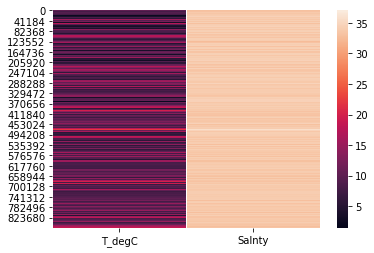

In [13]:
sns.heatmap(data = data[['T_degC', 'Salnty']])

In [15]:
data.dropna(inplace=True)

<ipython-input-15-f1116dacf2bb>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.dropna(inplace=True)


In [17]:
data.shape

(814247, 3)

In [18]:
data.isnull().sum()

Depthm    0
T_degC    0
Salnty    0
dtype: int64

<AxesSubplot:xlabel='Depthm', ylabel='Salnty'>

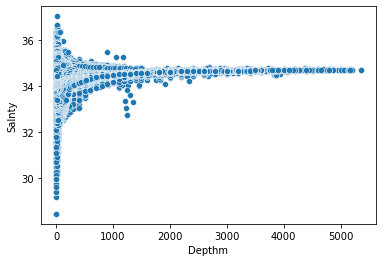

In [19]:
sns.scatterplot(x='Depthm', y='Salnty', data=data)

<AxesSubplot:xlabel='T_degC', ylabel='Salnty'>

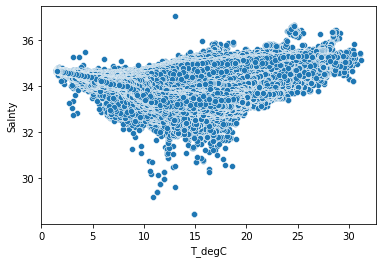

In [20]:
sns.scatterplot(x='T_degC', y='Salnty', data=data)

In [21]:
data.corr()

,Depthm,T_degC,Salnty
Depthm,1.000000,-0.676504,0.572867
T_degC,-0.676504,1.000000,-0.505266
Salnty,0.572867,-0.505266,1.000000


<AxesSubplot:xlabel='T_degC', ylabel='Count'>

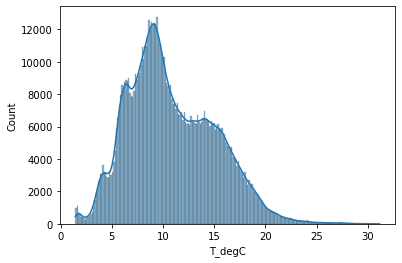

In [22]:
sns.histplot(x='T_degC', data=data, kde=True)

<AxesSubplot:xlabel='Depthm', ylabel='Count'>

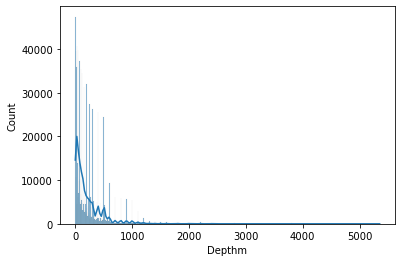

In [23]:
sns.histplot(x='Depthm', data=data, kde=True)

<AxesSubplot:xlabel='Salnty', ylabel='Count'>

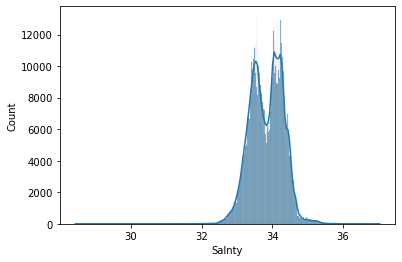

In [24]:
sns.histplot(x='Salnty', data=data, kde=True)

<AxesSubplot:xlabel='Salnty'>

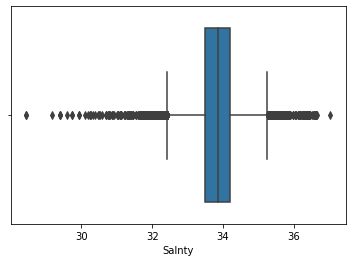

In [25]:
sns.boxplot(x='Salnty', data=data)

<AxesSubplot:xlabel='Depthm'>

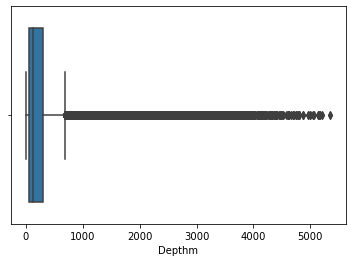

In [26]:
sns.boxplot(x='Depthm', data=data)

<AxesSubplot:xlabel='T_degC', ylabel='Count'>

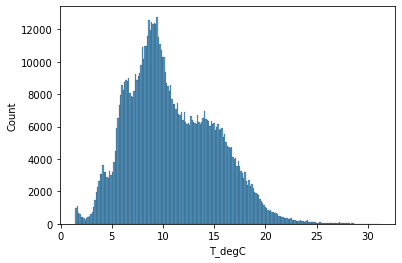

In [27]:
sns.histplot(x='T_degC',data=data)

In [29]:
X = data[['Depthm', 'Salnty']]
y = data[['T_degC']]

In [30]:
# Split X and y into X_
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=1)

In [31]:
lm = LinearRegression()
lm.fit(X_train, y_train)

LinearRegression()

In [32]:
lm.score(X_test, y_test)

0.4770121845202806

In [33]:
y_predict = lm.predict(X_test)

regression_model_mse = mean_squared_error(y_test, y_predict)

print(regression_model_mse)

9.299974277690731


In [34]:
import math

rmse = math.sqrt(regression_model_mse)
print(rmse)

3.0495859190537216


In [35]:
r2 = r2_score(y_test, y_predict)
print(r2)

0.4770121845202806


In [36]:
for i in range(2, 10):
    polynomial_features= PolynomialFeatures(degree=i)
    X_train_poly = polynomial_features.fit_transform(X_train)
    X_test_poly = polynomial_features.fit_transform(X_test)
    print("Polynomial Degree: ", i)
    plm = LinearRegression()
    plm.fit(X_train_poly, y_train)
    y_poly_pred = plm.predict(X_test_poly)
    r2 = r2_score(y_test,y_poly_pred)
    print("R-Squared: ", r2)

    regression_model_mse = mean_squared_error(y_poly_pred, y_test)
    rmse = np.sqrt(regression_model_mse)
    print("RMSE: ", rmse)

Polynomial Degree:  2
R-Squared:  0.7420530862248341
RMSE:  2.1417079871465674
Polynomial Degree:  3
R-Squared:  0.781443399074462
RMSE:  1.9714104400819012
Polynomial Degree:  4
R-Squared:  0.8024174182101982
RMSE:  1.8744308191874182
Polynomial Degree:  5
R-Squared:  0.8127307874853432
RMSE:  1.8248546577678324
Polynomial Degree:  6
R-Squared:  0.8098683539661309
RMSE:  1.8387483341978028
Polynomial Degree:  7
R-Squared:  0.8124900213166991
RMSE:  1.8260273602376922
Polynomial Degree:  8
R-Squared:  0.7417855062674661
RMSE:  2.1428185443162633
Polynomial Degree:  9
R-Squared:  0.4635857013200362
RMSE:  3.0884833273603816
